# 06. Figures for the report

**Purpose.** Draw the static charts for the report and save them as PNG files in `reports/figures/` (ignored by git). Every chart repeats a number that is already in a validated table, so a reader can check any picture against its table.

**Where the data comes from.**
- Daily series (growth of 100, drawdown, rolling Sharpe, price against total return) are recomputed from the database with `scripts/metrics.py`, exactly as in notebooks 02 and 05.
- The interval charts (Sharpe, beta, R-squared) read the CSV tables saved by notebooks 02 and 03, so each chart shows the same numbers as the table. Run notebooks 02 and 03 first.

**The seven figures.**
1. Growth of 100 invested at the 30 December 2020 close (price return).
2. Drawdown from the running peak.
3. Rolling 252-day Sharpe ratio.
4. Sharpe ratio by regime with 95% bootstrap interval.
5. Beta against the IHSG by regime with 95% HC3 interval.
6. R-squared by regime with 95% bootstrap interval.
7. Cumulative return on the price and the adjusted (total-return) basis, banks only.

**How to run.** Select the project `.venv` as the kernel, then use *Restart* and *Run All*. The notebook asks for the PostgreSQL user and password at the first data cell. It only reads from the database.

**Reading the charts.**
- Colours follow the instrument and never change: BBCA blue, BBRI orange, BMRI green, IHSG grey and dashed. Regimes are labelled along the top edge, with alternate bands shaded.
- Price returns exclude dividends. The IHSG has no dividends in this data, so figure 7 shows banks only.
- Everything is in-sample and descriptive.

In [1]:
import sys
import textwrap
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from matplotlib.patches import Patch

ROOT = Path.cwd() if (Path.cwd() / "scripts").exists() else Path.cwd().parent
sys.path.insert(0, str(ROOT / "scripts"))
try:
    import db_access
    import metrics
except ImportError as exc:
    raise ImportError(
        f"{exc}\nThis kernel is {sys.executable}. Select the project .venv kernel "
        "(top right of the notebook, Select Kernel > Python Environments > .venv), then Restart and Run All."
    ) from exc

print("project root:", ROOT)

project root: d:\Data Analyst\Portfolio


## 1. Load the data and the saved tables

Two database reads (`SELECT` only), then the CSV tables written by notebooks 02 and 03. If a CSV file is missing the notebook stops with a message saying which notebook to run.

In [2]:
conn = db_access.connect()
try:
    prices = db_access.load_prices(conn)
    sql = db_access.load_excess_returns(conn)
finally:
    conn.close()

REPORTS = ROOT / "reports"
NEEDED = {
    "02_sharpe_bootstrap.csv": "02_performance_risk",
    "02_rolling_sharpe_252.csv": "02_performance_risk",
    "02_performance_summary.csv": "02_performance_risk",
    "03_capm_regression.csv": "03_capm",
    "03_r2_bootstrap.csv": "03_capm",
}
missing = {f: nb for f, nb in NEEDED.items() if not (REPORTS / f).exists()}
if missing:
    raise FileNotFoundError("Missing saved tables: " + ", ".join(f"{f} (run {nb} first)" for f, nb in missing.items()))

sharpe_tbl = pd.read_csv(REPORTS / "02_sharpe_bootstrap.csv").set_index(["period", "ticker"])
capm_tbl = pd.read_csv(REPORTS / "03_capm_regression.csv").set_index(["period", "ticker"])
r2_tbl = pd.read_csv(REPORTS / "03_r2_bootstrap.csv").set_index(["period", "ticker"])
summary_tbl = pd.read_csv(REPORTS / "02_performance_summary.csv").set_index(["period", "ticker"])
rolling_saved = pd.read_csv(REPORTS / "02_rolling_sharpe_252.csv", index_col="trade_date", parse_dates=True)

print("prices rows:", len(prices), "| SQL view rows:", len(sql))

prices rows: 5536 | SQL view rows: 5524


## 2. Settings and drawing helpers

The helpers keep every figure consistent: thin lines, a quiet grid, regime labels along the top, direct labels at the right end of the line charts (the label text stays in ink, a coloured dot carries the identity), and a source line under each figure. Figures are saved at 200 dpi on a white background.

In [3]:
BANKS = ["BBCA", "BBRI", "BMRI"]
MARKET = "IHSG"
TICKERS = BANKS + [MARKET]
FIRST_RETURN_DAY = pd.Timestamp("2021-01-04")
PRIOR_CLOSE_DAY = pd.Timestamp("2020-12-30")
EXPECTED_DAYS = 1381
KNOWN_CUM = {"BBCA": -0.1027, "BBRI": -0.1717, "BMRI": 0.2680, "IHSG": 0.0154}
PERIODS = ["Full", "R1", "R2", "R3"]

COLORS = {"BBCA": "#2a78d6", "BBRI": "#eb6834", "BMRI": "#1baf7a", "IHSG": "#52514e"}
INK, MUTED, GRID = "#0b0b0b", "#52514e", "#d9d8d3"
SOURCE = "Source: Yahoo Finance (via yfinance), Bank Indonesia policy rate, own calculations. Daily data, 4 January 2021 to 30 September 2026."

FIG_DIR = REPORTS / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)
SAVED = []
results = []


def check(name, ok, detail=""):
    results.append(bool(ok))
    print(f"{'PASS' if ok else 'FAIL'}  {name}" + (f"  [{detail}]" if detail else ""))


def style(ax, title, ylabel=""):
    ax.set_title(title, loc="left", fontsize=12, color=INK, pad=22)
    ax.set_ylabel(ylabel, color=MUTED)
    ax.grid(axis="y", color=GRID, lw=0.6)
    ax.set_axisbelow(True)
    for side in ("top", "right"):
        ax.spines[side].set_visible(False)
    for side in ("left", "bottom"):
        ax.spines[side].set_color(GRID)
    ax.tick_params(colors=MUTED)


def shade_regimes(ax, first, last):
    for i, (name, (start, end)) in enumerate(metrics.REGIME_BOUNDS.items()):
        start, end = max(start, first), min(end, last)
        if i % 2 == 1:
            ax.axvspan(start, end, color=GRID, alpha=0.35, lw=0)
        ax.text(start + (end - start) / 2, 1.01, name, transform=ax.get_xaxis_transform(),
                ha="center", va="bottom", fontsize=8, color=MUTED)


def end_labels(ax, ends, x, fmt):
    ymin, ymax = ax.get_ylim()
    gap = 0.05 * (ymax - ymin)
    items = sorted(ends.items(), key=lambda kv: kv[1])
    ys = [v for _, v in items]
    for i in range(1, len(ys)):
        ys[i] = max(ys[i], ys[i - 1] + gap)
    for (name, value), y in zip(items, ys):
        ax.plot([x], [value], marker="o", ms=5, color=COLORS[name], clip_on=False)
        ax.text(x + pd.Timedelta(days=14), y, fmt(name, value), color=INK, va="center", fontsize=9)


def legend_outside(ax):
    ax.legend(frameon=False, loc="upper left", bbox_to_anchor=(1.01, 1.0), labelcolor=MUTED)


def footnote(fig, note=""):
    fig.text(0.01, 0.0, textwrap.fill(SOURCE + (" " + note if note else ""), 150), fontsize=8, color=MUTED, ha="left", va="top")


def save(fig, name):
    path = FIG_DIR / name
    fig.savefig(path, dpi=200, bbox_inches="tight", facecolor="white")
    SAVED.append(path)
    plt.show()


def dot_whisker(ax, table, value, low, high, tickers, spacing=0.15):
    offsets = np.arange(len(tickers)) - (len(tickers) - 1) / 2
    for off, t in zip(offsets, tickers):
        x = np.arange(len(PERIODS)) + off * spacing
        v = np.array([table.loc[(p, t), value] for p in PERIODS])
        lo = np.array([table.loc[(p, t), low] for p in PERIODS])
        hi = np.array([table.loc[(p, t), high] for p in PERIODS])
        ax.errorbar(x, v, yerr=[v - lo, hi - v], fmt="o", ms=6, lw=1.5, capsize=3, color=COLORS[t], label=t)
    ax.set_xticks(range(len(PERIODS)))
    ax.set_xticklabels([f"{p}\n({len(period_days[p])} days)" for p in PERIODS])

## 3. Series behind the figures

Returns, excess returns and regime day lists, built the same way as in notebooks 02 and 05. The checks confirm the series are the validated ones.

In [4]:
close = db_access.to_wide(prices, "close")[TICKERS]
adj = db_access.to_wide(prices, "adj_close")[TICKERS]
ret = metrics.simple_returns(close, FIRST_RETURN_DAY)
ret_adj = metrics.simple_returns(adj, FIRST_RETURN_DAY)
rate = sql.drop_duplicates("trade_date").set_index("trade_date")["rate_pct"].sort_index()
excess = metrics.excess_return(ret, metrics.daily_risk_free(rate))
LAST_DAY = close.index[-1]

labels = metrics.assign_regime(ret.index)
period_days = {"Full": ret.index}
period_days.update({name: ret.index[labels == name] for name in ("R1", "R2", "R3", "Stub")})

check(f"{EXPECTED_DAYS} return days, no missing values", len(ret) == EXPECTED_DAYS and not excess.isna().any().any())
check("regime day counts", [len(period_days[p]) for p in ("R1", "R2", "R3", "Stub")] == [399, 499, 393, 90])

PASS  1381 return days, no missing values
PASS  regime day counts


## Figure 1. Growth of 100

Each line is the split-adjusted close divided by the 30 December 2020 close, times 100 (price return, dividends excluded). The labels at the right give the final value.

PASS  growth of 100 ends at the confirmed cumulative price returns  [BBCA 89.7, BBRI 82.8, BMRI 126.8, IHSG 101.5]


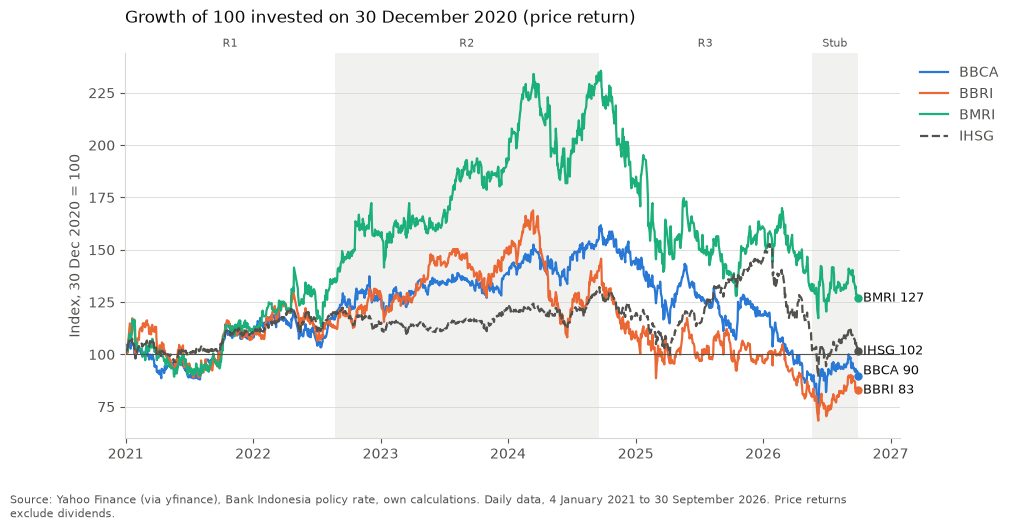

In [5]:
growth = close.loc[PRIOR_CLOSE_DAY:] / close.loc[PRIOR_CLOSE_DAY] * 100
check("growth of 100 ends at the confirmed cumulative price returns",
      all(abs(growth[t].iloc[-1] / 100 - 1 - KNOWN_CUM[t]) < 5e-5 for t in TICKERS),
      ", ".join(f"{t} {growth[t].iloc[-1]:.1f}" for t in TICKERS))

fig, ax = plt.subplots(figsize=(10, 5))
for t in TICKERS:
    ax.plot(growth.index, growth[t], color=COLORS[t], lw=1.6, ls="--" if t == MARKET else "-", label=t)
ax.axhline(100, color=MUTED, lw=0.8)
ax.set_xlim(PRIOR_CLOSE_DAY, LAST_DAY + pd.Timedelta(days=120))
shade_regimes(ax, PRIOR_CLOSE_DAY, LAST_DAY)
style(ax, "Growth of 100 invested on 30 December 2020 (price return)", "Index, 30 Dec 2020 = 100")
end_labels(ax, {t: growth[t].iloc[-1] for t in TICKERS}, growth.index[-1], lambda n, v: f"{n} {v:.0f}")
legend_outside(ax)
footnote(fig, "Price returns exclude dividends.")
save(fig, "fig1_growth_of_100.png")

## Figure 2. Drawdown from the running peak

Each line is the percentage below the highest close reached so far, from the 30 December 2020 close. The labels at the right give the drawdown on the last day; the lowest points are in the summary table. The sharp fall in early June 2026 and the rebound that followed were checked against the daily data (a market-wide move, not a data error).

PASS  worst drawdowns equal the saved summary table  [BBCA -55.71%, BBRI -59.53%, BMRI -50.20%, IHSG -41.52%]


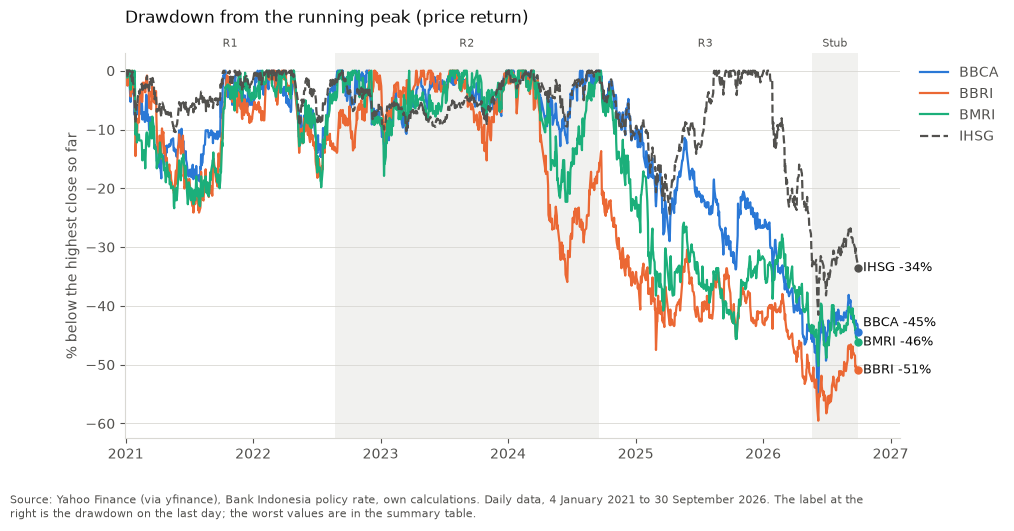

In [6]:
drawdown = metrics.drawdown_series(close.loc[PRIOR_CLOSE_DAY:]) * 100
dd_min = drawdown.min()
saved_mdd = summary_tbl.xs("Full", level="period")["mdd_pct"]
check("worst drawdowns equal the saved summary table", all(abs(dd_min[t] - saved_mdd[t]) < 0.0051 for t in TICKERS),
      ", ".join(f"{t} {dd_min[t]:.2f}%" for t in TICKERS))

fig, ax = plt.subplots(figsize=(10, 5))
for t in TICKERS:
    ax.plot(drawdown.index, drawdown[t], color=COLORS[t], lw=1.6, ls="--" if t == MARKET else "-", label=t)
ax.set_xlim(PRIOR_CLOSE_DAY, LAST_DAY + pd.Timedelta(days=120))
shade_regimes(ax, PRIOR_CLOSE_DAY, LAST_DAY)
style(ax, "Drawdown from the running peak (price return)", "% below the highest close so far")
end_labels(ax, {t: drawdown[t].iloc[-1] for t in TICKERS}, drawdown.index[-1], lambda n, v: f"{n} {v:.0f}%")
legend_outside(ax)
footnote(fig, "The label at the right is the drawdown on the last day; the worst values are in the summary table.")
save(fig, "fig2_drawdown.png")

## Figure 3. Rolling 252-day Sharpe ratio

The annualized Sharpe ratio over a moving window of 252 return days, using excess returns over the policy rate. The first value is on the 252nd return day. A window that straddles a regime boundary mixes two regimes.

PASS  rolling Sharpe equals the saved table  [max abs diff 4.44e-16]


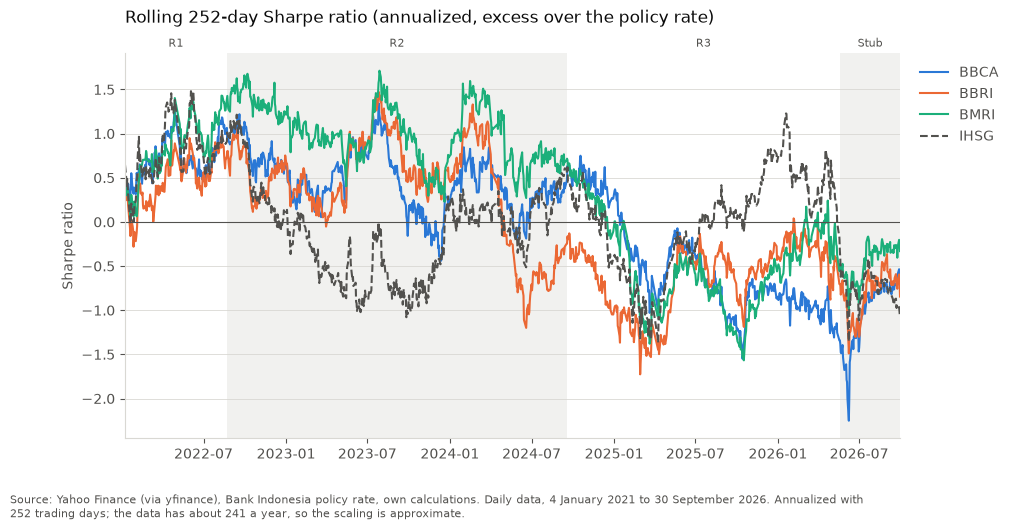

In [7]:
rolling = metrics.rolling_sharpe(excess, window=252).dropna()
d_roll = (rolling[TICKERS] - rolling_saved[TICKERS].reindex(rolling.index)).abs().max().max()
check("rolling Sharpe equals the saved table", len(rolling) == len(rolling_saved) and d_roll < 1e-9, f"max abs diff {d_roll:.2e}")

fig, ax = plt.subplots(figsize=(10, 5))
for t in TICKERS:
    ax.plot(rolling.index, rolling[t], color=COLORS[t], lw=1.5, ls="--" if t == MARKET else "-", label=t)
ax.axhline(0, color=MUTED, lw=0.8)
ax.set_xlim(rolling.index[0], LAST_DAY)
shade_regimes(ax, rolling.index[0], LAST_DAY)
style(ax, "Rolling 252-day Sharpe ratio (annualized, excess over the policy rate)", "Sharpe ratio")
legend_outside(ax)
footnote(fig, "Annualized with 252 trading days; the data has about 241 a year, so the scaling is approximate.")
save(fig, "fig3_rolling_sharpe.png")

## Figure 4. Sharpe ratio by regime

Annualized Sharpe ratio for each instrument over the full period and each regime, with the 95% stationary block-bootstrap interval (block 10 days, 10,000 resamples). Read from `02_sharpe_bootstrap.csv`. The Stub is left out: 90 days are too few for an interval. The intervals are descriptive; no test of differences is run.

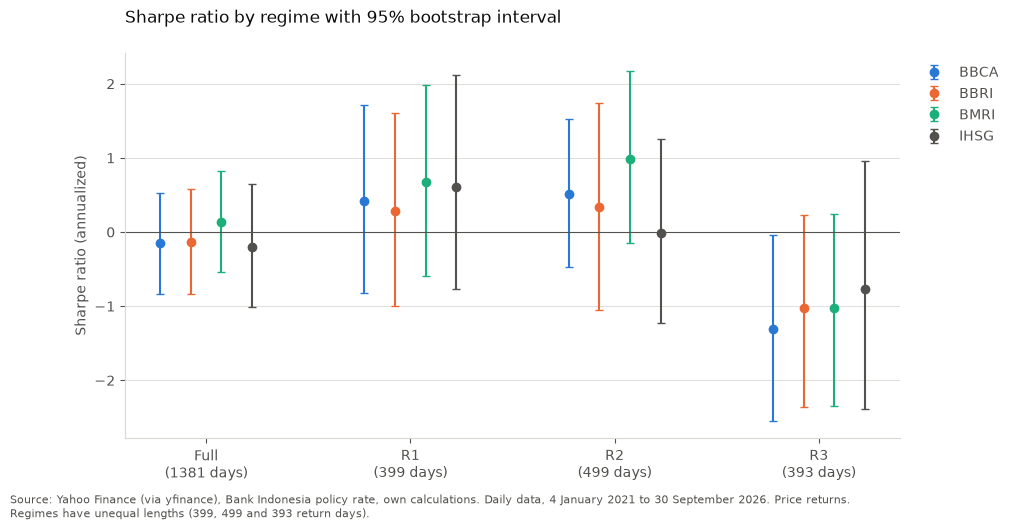

In [8]:
fig, ax = plt.subplots(figsize=(10, 5))
dot_whisker(ax, sharpe_tbl, "sharpe", "ci_low_b10", "ci_high_b10", TICKERS)
ax.axhline(0, color=MUTED, lw=0.8)
style(ax, "Sharpe ratio by regime with 95% bootstrap interval", "Sharpe ratio (annualized)")
legend_outside(ax)
footnote(fig, "Price returns. Regimes have unequal lengths (399, 499 and 393 return days).")
save(fig, "fig4_sharpe_by_regime.png")

## Figure 5. Beta against the IHSG

Beta from the regression of each bank's excess return on the IHSG excess return, with the 95% interval from HC3 robust standard errors. The dashed line is beta = 1. Read from `03_capm_regression.csv`. Twelve tests of beta = 1 are behind this chart and the p-values are not adjusted for that.

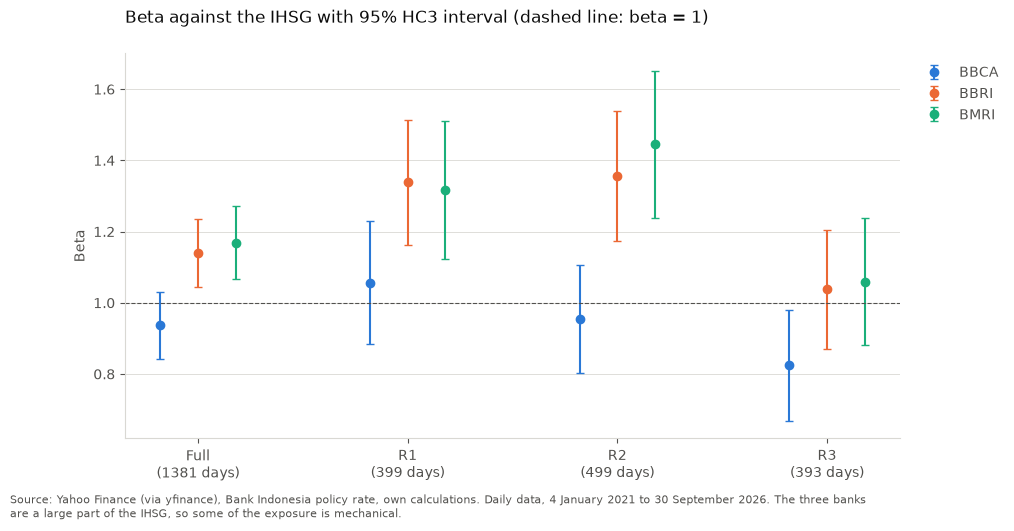

In [9]:
fig, ax = plt.subplots(figsize=(10, 5))
dot_whisker(ax, capm_tbl, "beta", "beta_ci_low", "beta_ci_high", BANKS, spacing=0.18)
ax.axhline(1, color=MUTED, lw=0.8, ls="--")
style(ax, "Beta against the IHSG with 95% HC3 interval (dashed line: beta = 1)", "Beta")
legend_outside(ax)
footnote(fig, "The three banks are a large part of the IHSG, so some of the exposure is mechanical.")
save(fig, "fig5_beta_by_regime.png")

## Figure 6. R-squared against the IHSG

The share of each bank's daily return variance explained by the IHSG, with the 95% stationary block-bootstrap interval (block 10 days). Read from `03_r2_bootstrap.csv`. The intervals for the differences between regimes (in the same file family) all include zero at block length 10.

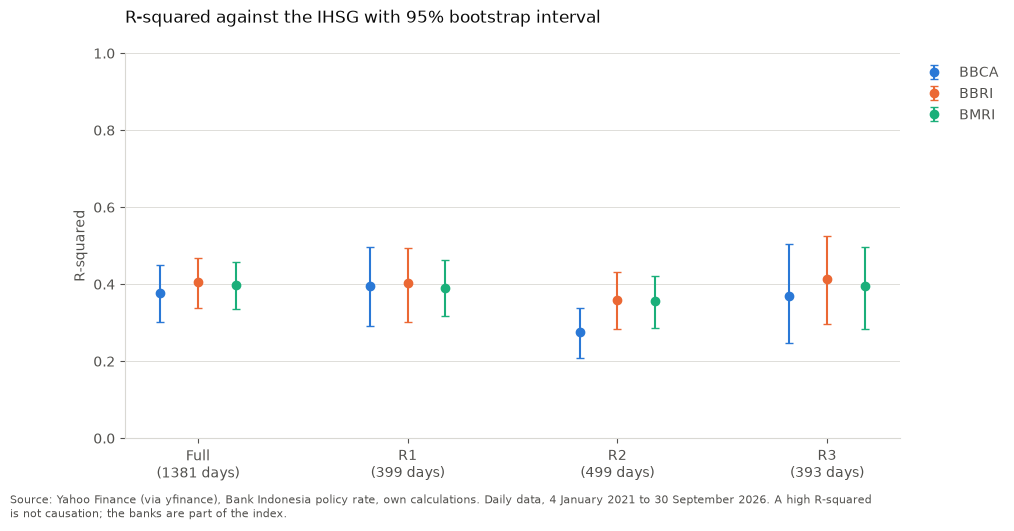

In [10]:
fig, ax = plt.subplots(figsize=(10, 5))
dot_whisker(ax, r2_tbl, "r2", "ci_low_b10", "ci_high_b10", BANKS, spacing=0.18)
ax.set_ylim(0, 1)
style(ax, "R-squared against the IHSG with 95% bootstrap interval", "R-squared")
legend_outside(ax)
footnote(fig, "A high R-squared is not causation; the banks are part of the index.")
save(fig, "fig6_r2_by_regime.png")

## Figure 7. Price return and total return

Cumulative return of each bank on the price basis (solid) and on the adjusted close, which includes dividends (hatched), for the full period and each regime. The IHSG is not shown: it has no dividend adjustment in this data, so a bank's total return cannot be compared like for like with the index.

PASS  price-basis cumulative returns equal the saved summary table
PASS  total return is at least the price return in every panel


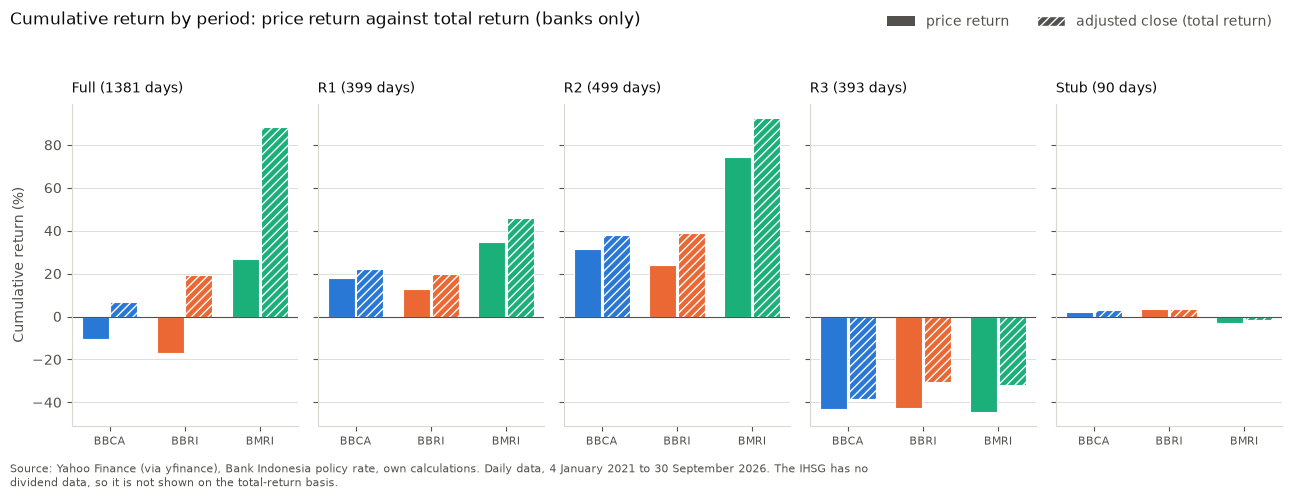

In [11]:
panels = ["Full", "R1", "R2", "R3", "Stub"]
cum = {basis: {p: metrics.cumulative_return(r.loc[period_days[p], BANKS]) * 100 for p in panels}
       for basis, r in (("price", ret), ("adj", ret_adj))}
saved_cum = summary_tbl["cum_return_pct"]
check("price-basis cumulative returns equal the saved summary table",
      all(abs(cum["price"][p][t] - saved_cum[(p, t)]) < 0.0051 for p in panels for t in BANKS))
check("total return is at least the price return in every panel",
      all(cum["adj"][p][t] >= cum["price"][p][t] - 1e-9 for p in panels for t in BANKS))

fig, axes = plt.subplots(1, len(panels), figsize=(13, 4.6), sharey=True)
for ax, p in zip(axes, panels):
    x = np.arange(len(BANKS))
    for k, (basis, hatch) in enumerate((("price", None), ("adj", "////"))):
        vals = [cum[basis][p][t] for t in BANKS]
        ax.bar(x + (k - 0.5) * 0.38, vals, width=0.36, color=[COLORS[t] for t in BANKS], hatch=hatch,
               edgecolor="white", lw=0.8)
    ax.axhline(0, color=MUTED, lw=0.8)
    ax.set_xticks(x)
    ax.set_xticklabels(BANKS, fontsize=8)
    style(ax, f"{p} ({len(period_days[p])} days)", "Cumulative return (%)" if p == panels[0] else "")
    ax.set_title(f"{p} ({len(period_days[p])} days)", loc="left", fontsize=10, color=INK, pad=8)
handles = [Patch(facecolor=MUTED, label="price return"), Patch(facecolor=MUTED, hatch="////", edgecolor="white", label="adjusted close (total return)")]
fig.legend(handles=handles, loc="upper right", ncol=2, frameon=False, labelcolor=MUTED, bbox_to_anchor=(0.99, 1.0))
fig.suptitle("Cumulative return by period: price return against total return (banks only)", x=0.01, ha="left", fontsize=12, color=INK)
fig.tight_layout(rect=(0, 0, 1, 0.93))
footnote(fig, "The IHSG has no dividend data, so it is not shown on the total-return basis.")
save(fig, "fig7_price_vs_total_return.png")

## Summary

Every check above must print PASS, and the seven figure files must exist in `reports/figures/`.

In [12]:
expected = ["fig1_growth_of_100.png", "fig2_drawdown.png", "fig3_rolling_sharpe.png", "fig4_sharpe_by_regime.png",
            "fig5_beta_by_regime.png", "fig6_r2_by_regime.png", "fig7_price_vs_total_return.png"]
check("all seven figure files were written and are not empty",
      [p.name for p in SAVED] == expected and all(p.exists() and p.stat().st_size > 10_000 for p in SAVED),
      str(FIG_DIR))

n_fail = results.count(False)
print(f"{len(results) - n_fail} passed, {n_fail} failed")
assert n_fail == 0, "At least one check failed. Investigate before using these figures."

PASS  all seven figure files were written and are not empty  [d:\Data Analyst\Portfolio\reports\figures]
8 passed, 0 failed
